In [90]:
import pandas as pd
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import graph
import ast

Import Bills data

In [47]:
billsPath =  os.path.join('..', 'data', 'raw', 'final_bill_data.csv')
billsDF = pd.read_csv(billsPath, engine='python')
billsDF

,bill_number,bill_url,title,text,sponsor,sponsor_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...","Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,Nothwithstanding any special or general law to...,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../downloaded_legislation/state/MA/192nd/2025/...
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...","Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,Department of Veterans’ Services,NaN,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../downloaded_legislation/state/MA/192nd/2025/...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67148,HD.77,https://malegislature.gov/Bills/194/HD77,An Act establishing a transferable pediatric c...,SECTION 1. Chapter 63 of the General Laws is h...,"Vaughn, Marcus S.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/194/HD77/House...,https://malegislature.gov/Bills/194/HD77.pdf,False,NaN,0,[],[],../downloaded_legislation/state/MA/194th/2025/...
67149,HD.76,https://malegislature.gov/Bills/194/HD76,An Act establishing school zones for locomotives,Chapter 160 of the General Laws is hereby amen...,"Vaughn, Marcus S.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/194/HD76/House...,https://malegislature.gov/Bills/194/HD76.pdf,False,NaN,0,[],[],../downloaded_legislation/state/MA/194th/2025/...
67150,HD.60,https://malegislature.gov/Bills/194/HD60,An Act relative to a sales tax exemption for t...,SECTION 1. Section 6 of chapter 64H of the Gen...,"Vaughn, Marcus S.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/194/HD60/House...,https://malegislature.gov/Bills/194/HD60.pdf,False,NaN,0,[],[],../downloaded_legislation/state/MA/194th/2025/...
67151,HD.83,https://malegislature.gov/Bills/194/HD83,An Act relative to requiring trauma kits in pu...,SECTION 1. This act shall be known and may be ...,"Vaughn, Marcus S.",https://malegislature.gov/Legislators/Profile/...,https://malegislature.gov/Bills/194/HD83/House...,https://malegislature.gov/Bills/194/HD83.pdf,False,NaN,0,[],[],../downloaded_legislation/state/MA/194th/2025/...


Import legislator data

In [29]:
legislatorsPath =  os.path.join('..', 'data', 'raw', 'extended_legislators.csv')
legislatorsDF = pd.read_csv(legislatorsPath, engine='python')
legislatorsDF

,url,First Name,Last Name,District,Party,committee_ids
0,https://malegislature.gov/Legislators/Profile/...,James,Arciero,2nd Middlesex,Democrat,[30]
1,https://malegislature.gov/Legislators/Profile/...,James,Arena-DeRosa,8th Middlesex,Democrat,"[1, 16, 23, 31]"
2,https://malegislature.gov/Legislators/Profile/...,Jennifer Balinsky,Armini,8th Essex,Democrat,"[12, 27, 30, 49]"
3,https://malegislature.gov/Legislators/Profile/...,Shirley,Arriaga,8th Hampden,Democrat,"[15, 21, 31, 32, 55]"
4,https://malegislature.gov/Legislators/Profile/...,Brian,Ashe,2nd Hampden,Democrat,"[5, 29, 45, 54]"
...,...,...,...,...,...,...
448,https://malegislature.gov/Legislators/Profile/...,Marie,Fleur,NaN,NaN,NaN
449,https://malegislature.gov/Legislators/Profile/...,Richard,Ross,NaN,NaN,NaN
450,https://malegislature.gov/Legislators/Profile/...,Robert,Nyman,NaN,NaN,NaN
451,https://malegislature.gov/Legislators/Profile/...,William,Lantigua,NaN,NaN,NaN


In [ ]:
# Mapping each bill and legislator to a unique node id
legislator_ids = list(legislatorsDF['url'].unique())
legislator_id_map = {url: idx for idx, url in enumerate(legislator_ids)}

bill_ids = list(billsDF['bill_url'])
bill_id_map = {url: idx + len(legislator_ids) for idx, url in enumerate(bill_ids)}

['https://malegislature.gov/Bills/192/H4147', 'https://malegislature.gov/Bills/192/S1263', 'https://malegislature.gov/Bills/192/H3682', 'https://malegislature.gov/Bills/192/SD3464', 'https://malegislature.gov/Bills/192/H2990', 'https://malegislature.gov/Bills/192/H1345', 'https://malegislature.gov/Bills/192/S1799', 'https://malegislature.gov/Bills/192/H3378', 'https://malegislature.gov/Bills/192/S887', 'https://malegislature.gov/Bills/192/S1633', 'https://malegislature.gov/Bills/192/H4517', 'https://malegislature.gov/Bills/192/SD3034', 'https://malegislature.gov/Bills/192/H1715', 'https://malegislature.gov/Bills/192/H3728', 'https://malegislature.gov/Bills/192/H627', 'https://malegislature.gov/Bills/192/H2093', 'https://malegislature.gov/Bills/192/H4844', 'https://malegislature.gov/Bills/192/H2569', 'https://malegislature.gov/Bills/192/S184', 'https://malegislature.gov/Bills/192/H277', 'https://malegislature.gov/Bills/192/H5306', 'https://malegislature.gov/Bills/192/HD5548', 'https://m

In [ ]:
print(legislator_id_map)
print(bill_id_map)

{'https://malegislature.gov/Bills/192/H4147': 453, 'https://malegislature.gov/Bills/192/S1263': 454, 'https://malegislature.gov/Bills/192/H3682': 455, 'https://malegislature.gov/Bills/192/SD3464': 456, 'https://malegislature.gov/Bills/192/H2990': 457, 'https://malegislature.gov/Bills/192/H1345': 458, 'https://malegislature.gov/Bills/192/S1799': 459, 'https://malegislature.gov/Bills/192/H3378': 460, 'https://malegislature.gov/Bills/192/S887': 461, 'https://malegislature.gov/Bills/192/S1633': 462, 'https://malegislature.gov/Bills/192/H4517': 463, 'https://malegislature.gov/Bills/192/SD3034': 464, 'https://malegislature.gov/Bills/192/H1715': 465, 'https://malegislature.gov/Bills/192/H3728': 466, 'https://malegislature.gov/Bills/192/H627': 467, 'https://malegislature.gov/Bills/192/H2093': 468, 'https://malegislature.gov/Bills/192/H4844': 469, 'https://malegislature.gov/Bills/192/H2569': 470, 'https://malegislature.gov/Bills/192/S184': 471, 'https://malegislature.gov/Bills/192/H277': 472, '

In [68]:

# Custom graph implemntation, adding bill nodes

mygraph = graph.CustomGraph()
for bill_url, bill_id  in bill_id_map.items():
    bill = billsDF[billsDF['bill_url'] == bill_url]
    billNode = graph.BillNode(bill_id, bill['bill_number'], bill_url, bill['title'], bill['text'], bill['sponsor'], bill['sponsor_url'], bill['view_text_url'], bill['download_pdf_url'], bill['is_home_rule'], bill['municipality'], bill['num_cosponsors'], bill['cosponsors'], bill['history'], bill['path'])
    mygraph.add_bill(billNode)


In [70]:
# Custom graph implementation, adding legislator nodes
for legislator_url, legislator_id  in legislator_id_map.items():
    legislator = legislatorsDF[legislatorsDF['url'] == legislator_url]
    legislatorNode = graph.LegislatorNode(legislator_id, legislator_url, legislator['First Name'], legislator['Last Name'], legislator['District'], legislator['Party'], legislator['committee_ids'] )
    mygraph.add_legislator(legislatorNode)

In [148]:
for bill_id, bill in mygraph.bill_nodes.items():
    sponsor = bill.sponsor
    sponsor_url = bill.sponsor_url.iloc[0]
    #print(sponsor_url)
    sponsor_id = None

    #adding bill <-> sponsor
    if sponsor_url in legislator_id_map.keys():
        sponsor_id = legislator_id_map[sponsor_url]
        mygraph.add_edge(bill_id, sponsor_id, 'sponsor')
    #adding bill <-> cosponsor
    cosponsors_raw = bill.cosponsors.iloc[0]
    cosponsors = []
    if isinstance(cosponsors_raw, str):
        cosponsors = ast.literal_eval(cosponsors_raw)
    else:
        cosponsors = cosponsors_raw  # already parsed
    if len(cosponsors) > 0:
        for cosponsor in list(cosponsors):
            # print(cosponsor)
            cosponsor_url = cosponsor['url'].split('/192')[0]
            if cosponsor_url in legislator_id_map.keys():
                cosponsor_id = legislator_id_map[cosponsor_url]
                mygraph.add_edge(bill_id, cosponsor_id, 'cosponsor')
    

In [149]:
print("Total edges:", len(mygraph.edges))
print("Sample edges:")
for edge in mygraph.edges[:5]:
    print(edge)


Total edges: 423234
Sample edges:
(453, 271, 'sponsor')
(454, 163, 'sponsor')
(455, 103, 'sponsor')
(457, 81, 'sponsor')
(458, 67, 'sponsor')


In [152]:
def get_subgraph(mygraph, root_id, depth=2):
    from collections import deque

    visited = set()
    sub_nodes = set()
    sub_edges = []

    queue = deque([(root_id, 0)])

    while queue:
        node_id, d = queue.popleft()
        if node_id in visited or d > depth:
            continue
        visited.add(node_id)
        sub_nodes.add(node_id)

        for src, dst, rel in mygraph.edges:
            if src == node_id or dst == node_id:
                neighbor = dst if src == node_id else src
                sub_edges.append((src, dst, rel))
                queue.append((neighbor, d + 1))

    return sub_nodes, sub_edges


453
Adding nodes
Adding edges
Drawing


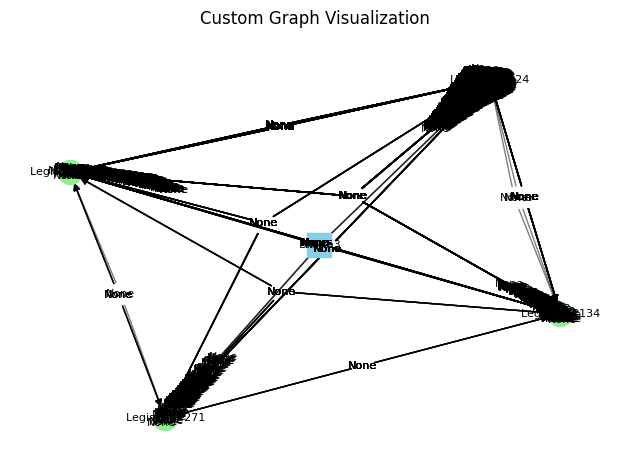

In [157]:
import networkx as nx
import matplotlib.pyplot as plt

def visualize_with_networkx(mygraph, root_id, depth=2):
    G = nx.DiGraph()

    sub_nodes, sub_edges = get_subgraph(mygraph, root_id, depth)

    G.add_node(str(root_id), label="Bill " + str(root_id), type='bill')

    # Add nodes
    print("Adding nodes")
    for node_id in sub_nodes:
        if node_id in mygraph.bill_nodes:
            G.add_node(str(node_id), label="Bill " +  str(node_id), type='bill')
        elif node_id in mygraph.legislator_nodes:
            G.add_node(str(node_id), label="Legislator " + str(node_id), type='legislator')

    # Add edges
    print("Adding edges")
    for src, dst, rel in sub_edges:
        G.add_edge(str(src), str(dst), label=rel)

    # Draw
    print("Drawing")
    pos = nx.spring_layout(G, seed=42)  # use spring layout for prettier layout
    bill_nodes = [n for n, d in G.nodes(data=True) if d.get('type') == 'bill']
    legislator_nodes = [n for n, d in G.nodes(data=True) if d.get('type') == 'legislator']

    nx.draw_networkx_nodes(G, pos, nodelist=bill_nodes, node_color='skyblue', node_shape='s', label='Bill')
    nx.draw_networkx_nodes(G, pos, nodelist=legislator_nodes, node_color='lightgreen', label='Legislator')
    nx.draw_networkx_edges(G, pos, alpha=0.5)
    nx.draw_networkx_labels(G, pos, labels={n: d.get('label') for n, d in G.nodes(data=True)}, font_size=8)

    plt.title("Custom Graph Visualization")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


sample_bill_id = bill_id_map['https://malegislature.gov/Bills/192/H4147']
print(sample_bill_id)
visualize_with_networkx(mygraph, sample_bill_id, 1)
